# Dans quelle mesure les conditions météorologiques expliquent-elles la consommation et la production d'électricité en France ?

Avec près de 28 % d'énergies renouvelables dans sa production d'électricité en 2024\* (hydraulique, éolien, solaire), la France est particulièrement exposée aux aléas météorologiques, du côté de l'offre autant que de la demande : la pluie alimente les barrages, le vent fait tourner les éoliennes, le soleil alimente le photovoltaïque, et les besoins en chauffage dépendent fortement de la température. A cette aune, nous avons choisi d'étudier ce phénomène à travers ce projet python.

\* Bilan électrique annuel 2024, RTE.

## Notre démarche

Si cette problématique est complexe et dépasse largement le cadre de ce projet, nous avons choisi d'y répondre par 5 hypothèses simples, que nous tenterons de confirmer ou d'infirmer à l'aide d'une analyse de données.

Voici ces 5 hypothèses :

**Consommation** : 
Nous nous attendons, à l'échelle annuelle, à une hausse de la consommation d'électricité lorsque les températures descendent en dessous d'un certain seuil (15 degrés), en raison du chauffage, mais également lorsqu'elles dépassent un autre seuil (27 degrés), à cause de la climatisation. 

**Production**  :
Nous chercherons à vérifier quatre hypothèses :

1. La production éolienne augmente avec la vitesse du vent. 
2. La production solaire suit l'ensoleillement : nulle la nuit, maximale vers midi et en été. 
3. La production hydraulique dépend des précipitations, avec un décalage dans le temps. 
4. La production nucléaire est peu sensible à la météo, sauf lors des canicules (limitations dues à la température des cours d'eau).

## Limitations et choix de modélisation

- Nos données sont limitées à la période 2021-2025, afin de travailler sur une période récente tout en excluant les confinements (2020), qui auraient ajouté du bruit aux données.
- Nous approchons la météo de chaque région par celle de sa plus grande ville (l'Île-de-France est représentée par Paris...). Cette hypothèse est forte, notamment pour l'éolien, dont la ressource peut varier fortement à l'échelle d'une région.
    - Paris : Île-de-France
    - Lyon : Auvergne-Rhône-Alpes
    - Toulouse : Occitanie
    - Bordeaux : Nouvelle-Aquitaine
    - Lille : Hauts-de-France
    - Strasbourg : Grand Est
    - Marseille : Provence-Alpes-Côte d'Azur
    - Nantes : Pays de la Loire
    - Rennes : Bretagne
    - Rouen : Normandie
    - Dijon : Bourgogne-Franche-Comté
    - Orléans : Centre-Val de Loire

## Sources et API utilisées

Deux API complémentaires ont été mobilisées :

- **éCO2mix (ODRE - Open Data Réseau Énergies)** : production et consommation d'électricité en France.
- **Open-Meteo** : données météorologiques détaillées (température, précipitations, vitesse du vent...) sur l'ensemble du territoire.

## Fichiers et organisation

- `data/` : jeux de données utilisés et leur mode de téléchargement .
- `Rendu_final.ipynb` : notebook retraçant l'ensemble du déroulé du projet, de la collecte des données à l'analyse des hypothèses.
- `src` : Fichier dans lequel se trouvent les fichier py dans lesquel toutes les fonctions utilisées dans le rendu final sont détaillées. 

# I. Présentation et préparation des données

## API Open-Météo
On va commencer par une présentation rapide des données brutes (meteo_pur), telles qu'on les a téléchargées. Puis on détaillera le traitement qu'on leur a appliqué, et enfin on explorera ces données plus en détail à l'aide de statistiques descriptives.


In [1]:
from src.meteo import charger_meteo
from IPython.display import display #Pour afficher des beaux tableaux


#On appelle meteo_pur la data sans aucun traitement telle qu'on  l'a téléchargée de Open Meteo
meteo_pur= charger_meteo("data/raw/openmeteo") 

#Voila un aperçu des données
print(display(meteo_pur.head()), display(meteo_pur.describe()))

#On observe bien que nos données couvre du premier janvier 2021 au 31 décembre 2025
print( "Les données couvrent de "+ str(meteo_pur["time"].min()) +" à " +str( meteo_pur["time"].max()))

#On observe bien que les 12 régions de la France métropolitaine (13 - la Corse) sont bien présentes (1 ville par région)
print("On observe bien au total "+str(meteo_pur["ville"].nunique() )+" régions")



,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville
0,2021-01-01 00:00:00+00:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux
1,2021-01-01 01:00:00+00:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux
2,2021-01-01 02:00:00+00:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux
3,2021-01-01 03:00:00+00:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux
4,2021-01-01 04:00:00+00:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux


,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation
count,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000,525888.000000
mean,12.986467,151.895489,61.493029,12.207613,20.616850,0.099247
std,7.283659,227.364982,41.271378,6.945876,10.762091,0.457567
min,-11.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.900000,0.000000,15.000000,7.100000,12.800000,0.000000
50%,12.700000,7.000000,83.000000,10.900000,19.700000,0.000000
75%,18.000000,249.000000,100.000000,16.000000,26.800000,0.000000
max,41.700000,958.000000,100.000000,69.900000,102.400000,24.400000


None None
Les données couvrent de 2021-01-01 00:00:00+00:00 à 2025-12-31 23:00:00+00:00
On observe bien au total 12 régions


Tout d'abord, on a bien 525 888 lignes : nos données couvrent la période attendue (de janvier 2021 à décembre 2025) et les douze régions (dans toute la suite, ces régions seront représentées par leur plus grande ville), à savoir la France métropolitaine sans la Corse. 

Première remarque sur les données : on peut observer que la température moyenne est d'environ 13 °C, ce qui est considéré comme froid selon notre convention. 
C'est l'effet de la nuit sur la température moyenne : certains jours chauds d'été ont une température inférieure à 15 °C la nuit, mais ne sont pas froids pour autant. On prendra ce problème en compte dans le traitement des données en considérant les jours froids comme ayant une température moyenne sous 15 °C, et les jours chauds comme ayant une température maximale au-dessus de 27 °C. 

On observe aussi que les valeurs ne sont pas aberrantes (une température maximale de 41,7 °C et une minimale de −11 °C). Par curiosité, on aimerait savoir dans quelle ville on atteint tel ou tel extremum météorologique. Par exemple, si l'on s'intéresse aux températures minimales dans les douze villes et à la vitesse du vent maximale à 100 m à Paris :


In [2]:
from src.meteo import extremum_meteo
print(display(extremum_meteo(meteo_pur, "temperature_2m", mode="min")),display(extremum_meteo(meteo_pur, "wind_speed_100m", mode="max", ville="paris")))

,ville,time,valeur
0,bordeaux,2022-12-17 07:00:00+01:00,-4.8
1,dijon,2021-02-13 08:00:00+01:00,-8.6
2,lille,2021-02-09 07:00:00+01:00,-7.6
3,lyon,2021-02-14 08:00:00+01:00,-7.0
4,marseille,2023-12-03 08:00:00+01:00,-0.5
5,nantes,2024-01-20 09:00:00+01:00,-3.9
6,orleans,2021-02-13 08:00:00+01:00,-6.4
7,paris,2024-01-20 01:00:00+01:00,-6.1
8,rennes,2024-01-19 05:00:00+01:00,-5.4
9,rouen,2021-02-10 08:00:00+01:00,-6.3


,ville,time,valeur
0,paris,2021-10-21 05:00:00+02:00,76.7


None None


A noter que notre fonction ne garde qu'une date à chaque fois, donc il  y a potentiellement pleins de dates ex-aequo (par exemple sur le minimum de la vitesse du vent, il y aura beaucoup de date à 0km/h mais une seule gardée).

In [3]:
from src.meteo import preparer_meteo
#Les données sont globalement déjà propres
print("pour chaque variable, on vérifie bien qu'on a toutes les observations", meteo_pur.isna().sum(), "puis combien de doublon il y a",meteo_pur.duplicated(["ville", "time"]).sum())
#Les noms de colonnes sont également assez explicites donc on a pas vraiment trouvé d'intérêt à les renommer.



pour chaque variable, on vérifie bien qu'on a toutes les observations time                   0
temperature_2m         0
shortwave_radiation    0
cloud_cover            0
wind_speed_10m         0
wind_speed_100m        0
precipitation          0
ville                  0
dtype: int64 puis combien de doublon il y a 0


Les données telles qu'elles sont importées sont déjà assez propres (pas de doublons ni de valeurs manquantes). On va cependant enrichir la base avec quelques nouvelles colonnes :
- deux colonnes booléennes indiquant si la température est sous 15 °C ou au-dessus de 27 °C (sous_15, sup_27) 
- deux colonnes indiquant de combien la température est en dessous ou au-dessus des seuils respectifs (deg_sous_15, deg_sup_27) 
- la température maximale (tmax_jour) et la moyenne (tmoy_jour) de chaque jour, ainsi que le fait que le jour soit chaud (tmax > 27) ou froid (tmoy < 15) 
- la vitesse maximale et la vitesse moyenne du vent à 100 mètres de la journée


In [4]:
meteo = preparer_meteo(meteo_pur) 
meteo.head()

,time,temperature_2m,shortwave_radiation,cloud_cover,wind_speed_10m,wind_speed_100m,precipitation,ville,jour,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,2021-01-01 01:00:00+01:00,4.4,0.0,95,3.1,5.5,0.0,bordeaux,2021-01-01,True,False,10.6,0.0,6.1,3.752174,False,True,18.308696,28.0
1,2021-01-01 02:00:00+01:00,3.3,0.0,96,3.4,3.5,0.0,bordeaux,2021-01-01,True,False,11.7,0.0,6.1,3.752174,False,True,18.308696,28.0
2,2021-01-01 03:00:00+01:00,2.1,0.0,92,5.4,5.8,0.0,bordeaux,2021-01-01,True,False,12.9,0.0,6.1,3.752174,False,True,18.308696,28.0
3,2021-01-01 04:00:00+01:00,1.9,0.0,92,5.9,12.0,0.0,bordeaux,2021-01-01,True,False,13.1,0.0,6.1,3.752174,False,True,18.308696,28.0
4,2021-01-01 05:00:00+01:00,1.8,0.0,82,6.6,16.6,0.0,bordeaux,2021-01-01,True,False,13.2,0.0,6.1,3.752174,False,True,18.308696,28.0


## Rapide exploration des données d'Open Meteo

Nous allons effectuer quelques graphiques utiles pour explorer nos données et pour plus tard considérer nos hypothèses.

Tout d'abords pour vérifier la corrélation entre production d'énérgie hydraulique et précipatation, il sera utile d'avoir un graphe des précipitations. On regroupe les données par mois et on affiche le graphique pour Bordeaux.

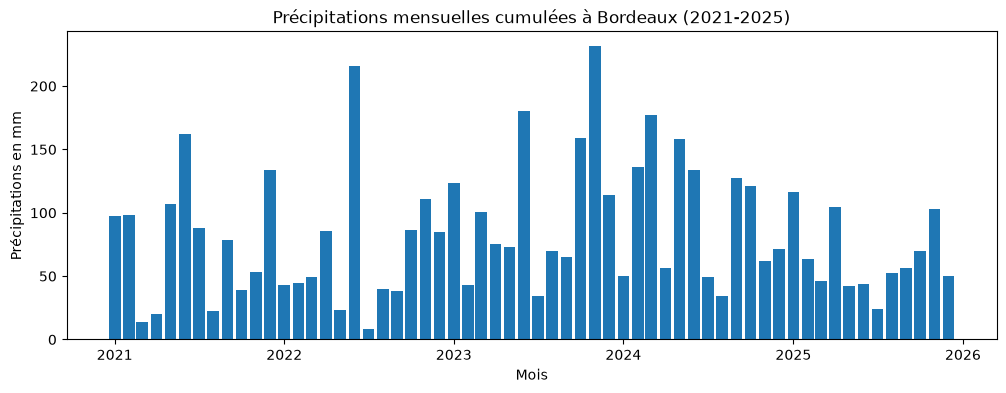

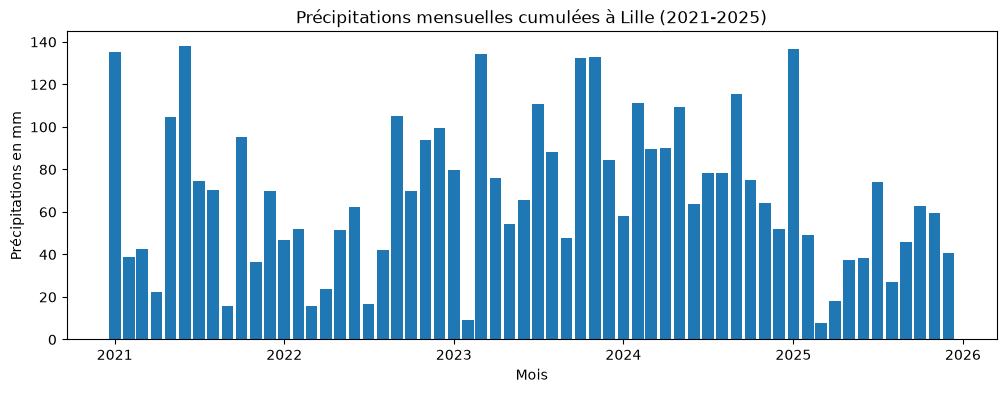

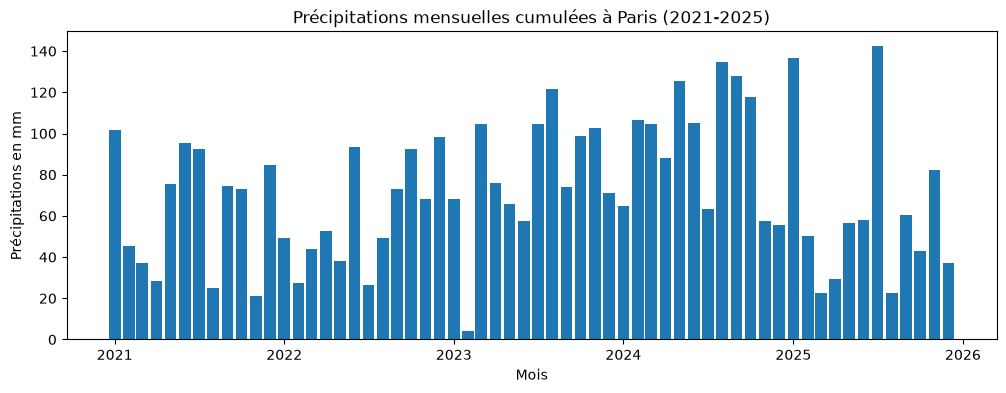

In [5]:
import matplotlib.pyplot as plt
from src.meteo import tracer_cumul_mensuel_precipitation
ville = "bordeaux" #en tant que bordelais je peux attester que Bordeaux devrait être riche en données sur ce point !
tracer_cumul_mensuel_precipitation(meteo, ville)
tracer_cumul_mensuel_precipitation(meteo, "lille")
tracer_cumul_mensuel_precipitation(meteo, "paris")

On peut observer que les précipitations sont irrégulières sans vrai cycle apparant mais qu'on retrouve certains éléments en communs entre les villes, ce qui est attendu (chute début 2023, pic à la fin de l'année qui s'abaisse jusqu'à janvier 2024 par exemple)

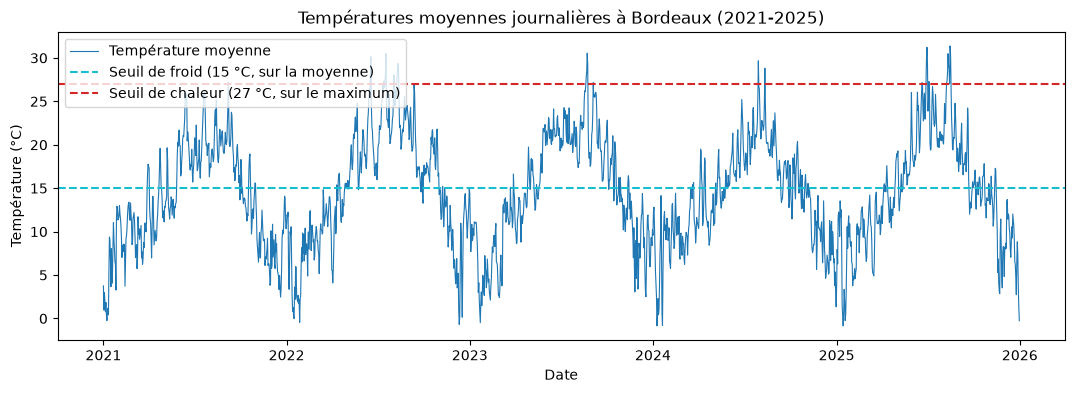

In [6]:

from src.meteo import tracer_temperature_moyenne_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tracer_temperature_moyenne_jour(meteo,ville)

Tout d'abords il est rassurant de noter que l'on aperçoit les saisons sur ce graphe !

Ensuite pour ce qui est de notre analyse,on observe que très peu de jours sont au dessus du seuil de chaleur (27 degré). C'est "l'effet nuit" qu'on a déjà mentionné. On va donc considérer la température maximal journalière pour ce seuil chaud.

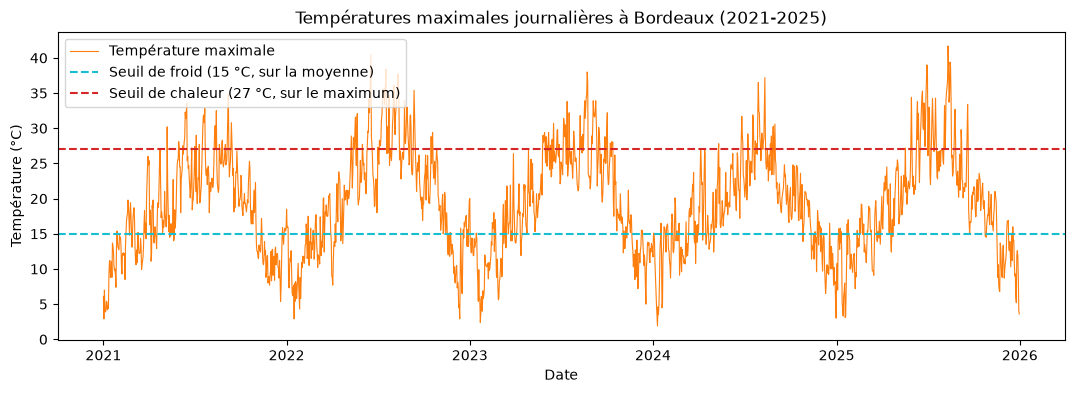

In [7]:
from src.meteo import tracer_temperature_max_jour, SEUIL_FROID, SEUIL_CHAUD

ville = "bordeaux"
tracer_temperature_max_jour(meteo,ville)


Beaucoup plus de jours sont alors considérés comme chaud. On voudrait maintenant savoir exactement combien de jours sont considérés comme chaud ou froid.

In [8]:
# Un seul enregistrement par ville et par jour
jours = meteo.drop_duplicates(["ville", "jour"])

# Nombre de jours froids par ville (2021-2025)
jours_froids = jours.groupby("ville")["jour_froid"].sum().sort_values(ascending=False)
print("Jours froids par ville :")
print(jours_froids)

# Nombre de jours chauds par ville (2021-2025)
jours_chauds = jours.groupby("ville")["jour_chaud"].sum().sort_values(ascending=False)
print("\nJours chauds par ville :")
print(jours_chauds)

Jours froids par ville :
ville
rouen         1233
lille         1220
dijon         1192
rennes        1168
paris         1156
orleans       1152
strasbourg    1145
nantes        1090
lyon          1084
bordeaux       994
toulouse       986
marseille      857
Name: jour_froid, dtype: int64

Jours chauds par ville :
ville
toulouse      349
marseille     310
lyon          293
bordeaux      265
strasbourg    198
dijon         171
paris         161
orleans       158
nantes        147
rennes        122
rouen          85
lille          82
Name: jour_chaud, dtype: int64


On retrouve le fait qu'il y a beaucoup plus de jours froids que de jours chauds, mais également que les villes du Nord sont beaucoup plus froides que les villes du Sud, et inversement (rien de très surprenant).

On va faire le même travail pour la vitesse du vent à 100 m (les éoliennes faisant plus de 100 m de haut, c'est la valeur pertinente).

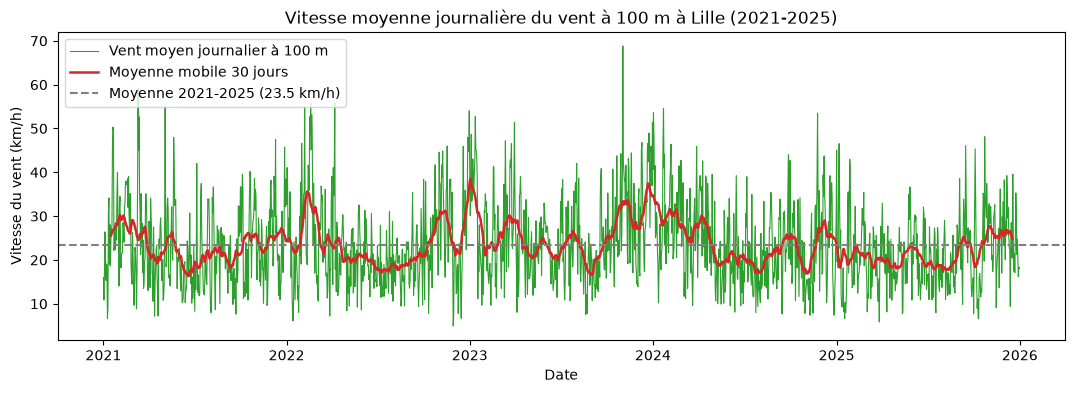

In [9]:
from src.meteo import tracer_vent_moyen_jour

ville = "lille"
tracer_vent_moyen_jour(meteo, ville)

Ces valeurs varient énormèment du jour au lendemain donc pour rendre le graphique plus lisible on a rajouté une moyenne mobible sur un mois.

## API éCO2mix

Nous présentons maintenant les données d'électricité (consommation et production par filière, par région et par demi-heure), puis leur préparation et quelques statistiques descriptives.


In [10]:
from src.electricite import charger_eco2mix, preparer_eco2mix, tracer_moyennes_par_region, COLONNES_ELEC
from src.meteo import SEUIL_FROID, SEUIL_CHAUD
import pandas as pd
import matplotlib.pyplot as plt


elec_pur = charger_eco2mix()

#Aperçu des données
display(elec_pur.head())

#Vérification de la période couverte et du nombre de régions
print("Les données couvrent de " + str(elec_pur["date_heure"].min()) + " à " + str(elec_pur["date_heure"].max()))
print("On observe au total " + str(elec_pur["code_insee_region"].nunique()) + " régions")


,code_insee_region,libelle_region,date_heure,consommation,nucleaire,eolien,solaire,hydraulique
0,44,Grand Est,2025-12-31T23:30:00+00:00,5870.0,8963.0,45,0.0,524.0
1,11,Île-de-France,2025-12-31T23:30:00+00:00,10410.0,0.0,0,0.0,5.0
2,52,Pays de la Loire,2025-12-31T23:30:00+00:00,4569.0,0.0,934,0.0,3.0
3,24,Centre-Val de Loire,2025-12-31T23:30:00+00:00,3139.0,10323.0,148,0.0,3.0
4,76,Occitanie,2025-12-31T23:30:00+00:00,6387.0,1247.0,55,0.0,1377.0


Les données couvrent de 2021-01-01T00:00:00+00:00 à 2025-12-31T23:30:00+00:00
On observe au total 12 régions


In [11]:
#On passe de la demi-heure à l'heure (moyenne des deux demi-heures, car ce sont des puissances en MW)
#et on associe à chaque région sa plus grande ville, pour pouvoir fusionner avec la météo
elec_horaire = preparer_eco2mix(elec_pur)

display(elec_horaire.head())
print("Nombre de lignes : " + str(len(elec_horaire)))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville
0,11,2021-01-01 00:00:00+00:00,9495.0,0.0,1.0,0.0,3.0,paris
1,11,2021-01-01 01:00:00+00:00,9061.0,0.0,1.5,0.0,3.0,paris
2,11,2021-01-01 02:00:00+00:00,8690.0,0.0,0.0,0.0,3.0,paris
3,11,2021-01-01 03:00:00+00:00,8429.0,0.0,0.0,0.0,3.0,paris
4,11,2021-01-01 04:00:00+00:00,8446.5,0.0,0.5,0.0,3.0,paris


Nombre de lignes : 525828


Après passage à l'heure, on obtient 525 828 lignes au lieu des 525 888 attendues (12 villes × 1 826 jours × 24 heures). Il manque une heure par an et par région : celle du passage à l'heure d'hiver en octobre (00h-01h UTC), absente des données RTE. Ces 60 heures, soit 0,01 % des données, seront écartées lors de la jointure avec la météo.


In [12]:
#Statistiques descriptives des données d'électricité horaires (en MW)
display(elec_horaire[COLONNES_ELEC].describe().round(0))

#On vérifie qu'il n'y a ni valeur manquante ni doublon (une seule ligne par ville et par heure)
print("Valeurs manquantes : " + str(elec_horaire.isna().sum().sum()))
print("Doublons ville-heure : " + str(elec_horaire.duplicated(["ville", "time"]).sum()))


,consommation,nucleaire,eolien,solaire,hydraulique
count,525828.0,525828.0,525828.0,525828.0,525828.0
mean,4256.0,3222.0,424.0,212.0,581.0
std,2020.0,3545.0,663.0,461.0,997.0
min,430.0,0.0,0.0,0.0,0.0
25%,2632.0,0.0,51.0,0.0,6.0
50%,3970.0,2358.0,187.0,4.0,56.0
75%,5390.0,6188.0,518.0,186.0,844.0
max,14688.0,13686.0,5870.0,4849.0,8277.0


Valeurs manquantes : 0
Doublons ville-heure : 0


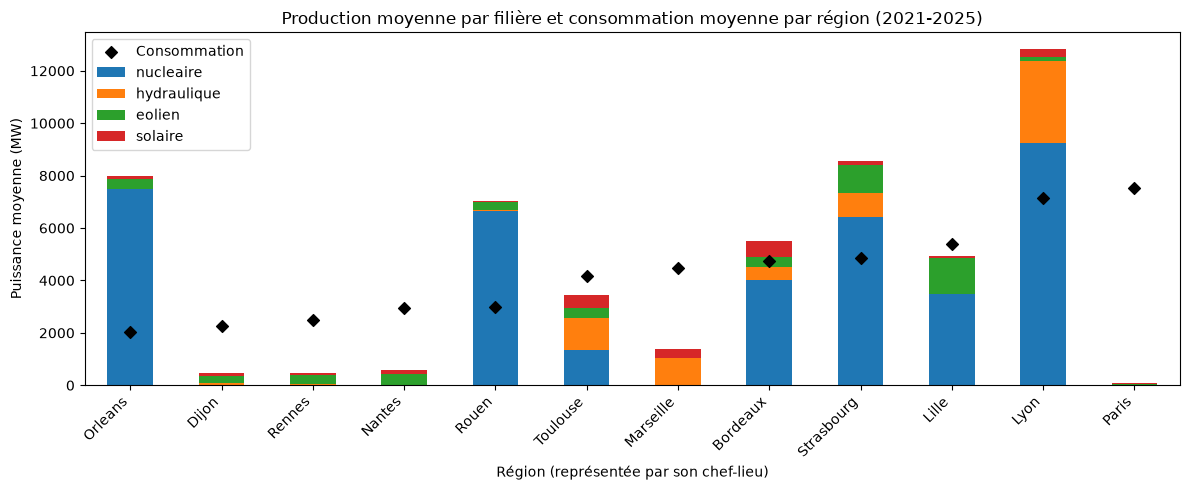

,consommation,nucleaire,eolien,solaire,hydraulique
ville,,,,,
orleans,2017.0,7492.0,363.0,130.0,14.0
dijon,2277.0,0.0,251.0,107.0,102.0
rennes,2485.0,0.0,327.0,66.0,67.0
nantes,2956.0,0.0,414.0,154.0,3.0
rouen,2997.0,6670.0,308.0,40.0,13.0
toulouse,4183.0,1360.0,391.0,510.0,1190.0
marseille,4488.0,0.0,24.0,336.0,1022.0
bordeaux,4754.0,4009.0,381.0,623.0,498.0
strasbourg,4868.0,6412.0,1041.0,182.0,938.0


In [13]:
moyennes_region = tracer_moyennes_par_region(elec_horaire)
display(moyennes_region)


**Statistiques descriptives des données d'électricité**

Les données horaires ne comportent ni valeur manquante ni doublon : chaque ville a une seule ligne par heure.

Le tableau `describe()` montre que la consommation horaire moyenne d'une région est de 4 256 MW, avec de fortes variations
(de 430 à 14 688 MW selon la région, l'heure et la saison). Pour le nucléaire, la médiane (2 358 MW) est nettement inférieure
à la moyenne (3 222 MW) et le premier quartile vaut 0 : cinq régions n'ont aucune centrale (Île-de-France, Bourgogne-Franche-Comté,
Bretagne, Pays de la Loire, PACA). Pour le solaire, la médiane n'est que de 4 MW, car la production est nulle la nuit, soit près
de la moitié des heures.

Le graphique met en évidence des profils régionaux très différents :
- l'**Île-de-France** (Paris) est la région qui consomme le plus (7 514 MW en moyenne) mais ne produit presque rien : elle dépend
  entièrement des autres régions ;
- le **Centre-Val de Loire** (Orléans) et la **Normandie** (Rouen) produisent bien plus qu'elles ne consomment, grâce au nucléaire
  (près de 4 fois sa consommation pour le Centre-Val de Loire) ;
- l'**Auvergne-Rhône-Alpes** (Lyon) est la première région productrice, avec beaucoup de nucléaire et d'hydraulique (Alpes, Rhône) ;
- l'**éolien** est surtout présent dans les Hauts-de-France (Lille) et le Grand Est (Strasbourg), l'**hydraulique** dans les régions
  de montagne (Lyon, Toulouse, Marseille), le **solaire** dans le Sud-Ouest (Bordeaux, Toulouse).

Ces différences justifient de mener l'analyse région par région, et de limiter l'étude du nucléaire aux sept régions qui en produisent.

*Limite :* seules quatre filières ont été récupérées. Le thermique (gaz) et les bioénergies ne sont pas inclus, la production totale
des régions est donc légèrement sous-estimée.


# II Jointure entre les deux bases de données

In [14]:
#On fusionne l'électricité (elec_horaire) et la météo préparée (meteo) sur la ville et l'heure.
#Les deux colonnes time ont des fuseaux différents (UTC et Paris) mais pandas les compare comme des instants.
donnees = pd.merge(elec_horaire, meteo, on=["ville", "time"], how="inner")
#Après la fusion, time est en UTC (fuseau du tableau de gauche) : on le remet en heure française pour les analyses par heure
donnees["time"] = donnees["time"].dt.tz_convert("Europe/Paris")

display(donnees.head())
print("Nombre de lignes après jointure : " + str(len(donnees)))
print("Valeurs manquantes : " + str(donnees.isna().sum().sum()))


,code_insee_region,time,consommation,nucleaire,eolien,solaire,hydraulique,ville,temperature_2m,shortwave_radiation,...,sous_15,sup_27,deg_sous_15,deg_sup_27,tmax_jour,tmoy_jour,jour_chaud,jour_froid,vent100_moy_jour,vent100_max_jour
0,11,2021-01-01 01:00:00+01:00,9495.0,0.0,1.0,0.0,3.0,paris,-0.6,0.0,...,True,False,15.6,0.0,3.6,0.291304,False,True,8.995652,12.7
1,11,2021-01-01 02:00:00+01:00,9061.0,0.0,1.5,0.0,3.0,paris,-1.6,0.0,...,True,False,16.6,0.0,3.6,0.291304,False,True,8.995652,12.7
2,11,2021-01-01 03:00:00+01:00,8690.0,0.0,0.0,0.0,3.0,paris,-2.0,0.0,...,True,False,17.0,0.0,3.6,0.291304,False,True,8.995652,12.7
3,11,2021-01-01 04:00:00+01:00,8429.0,0.0,0.0,0.0,3.0,paris,-1.8,0.0,...,True,False,16.8,0.0,3.6,0.291304,False,True,8.995652,12.7
4,11,2021-01-01 05:00:00+01:00,8446.5,0.0,0.5,0.0,3.0,paris,-1.9,0.0,...,True,False,16.9,0.0,3.6,0.291304,False,True,8.995652,12.7


Nombre de lignes après jointure : 525816
Valeurs manquantes : 0


La jointure donne 525 816 lignes. On perd les 60 heures absentes d'éCO2mix au passage à l'heure d'hiver, ainsi que la dernière heure du 31/12/2025, qui tombe en 2026 en heure française. Il n'y a aucune valeur manquante : les deux bases sont prêtes pour l'analyse.


# III Analyses de nos hypothèses

## Consommation

*Hypothèse :* la consommation d'électricité augmente lorsque la température passe sous 15 °C (chauffage) ou au-dessus de 27 °C (climatisation).


In [15]:
#Hypothèse consommation : on passe à l'échelle du jour pour neutraliser l'effet jour/nuit.
#Pour chaque ville et chaque jour, on calcule la consommation moyenne et la température moyenne.
conso_jour = (donnees
              .groupby(["ville", "jour"])[["consommation", "temperature_2m"]]
              .mean()
              .reset_index())

print("Nombre de jours × villes : " + str(len(conso_jour)))


Nombre de jours × villes : 21912


On obtient 21 912 lignes, soit 12 villes × 1 826 jours (du 1er janvier 2021 au 31 décembre 2025, 2024 étant bissextile). Chaque ligne correspond à une ville et un jour : la consommation et la température y sont la moyenne des heures de la journée.


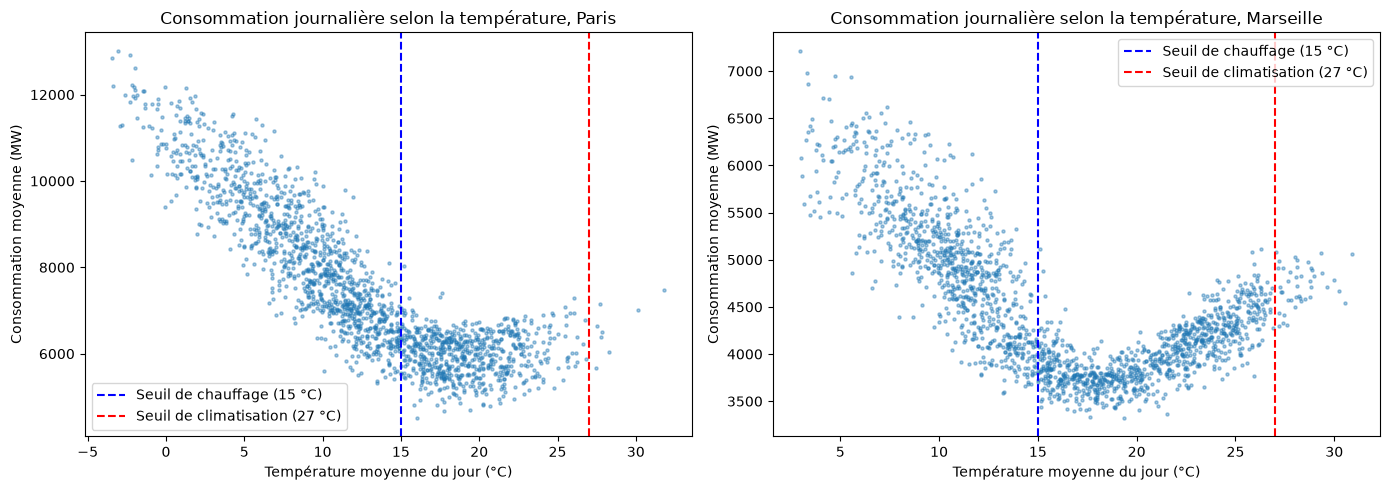

In [16]:
villes = ["paris", "marseille"]

# 1 ligne, 2 colonnes : axes est une liste de 2 graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# zip associe chaque ville à son graphique : (paris, axes[0]), (marseille, axes[1])
for ville, ax in zip(villes, axes):
    d = conso_jour[conso_jour["ville"] == ville]
    ax.scatter(d["temperature_2m"], d["consommation"], s=5, alpha=0.4)
    ax.axvline(SEUIL_FROID, color="blue", linestyle="--", label="Seuil de chauffage (" + str(SEUIL_FROID) + " °C)")
    ax.axvline(SEUIL_CHAUD, color="red", linestyle="--", label="Seuil de climatisation (" + str(SEUIL_CHAUD) + " °C)")
    ax.set_title("Consommation journalière selon la température, " + ville.capitalize())
    ax.set_xlabel("Température moyenne du jour (°C)")
    ax.set_ylabel("Consommation moyenne (MW)")
    ax.legend()

plt.tight_layout()   # évite que les titres et les axes se chevauchent
plt.show()




**I/ Paris**

1. *Sous le seuil de 15 °C.* On observe une relation forte et presque linéaire : plus il fait froid, plus on consomme. On passe d'environ 6 500 MW vers 15 °C à environ 12 000 MW vers -2 °C. C'est l'effet du chauffage électrique.
2. *Entre 15 °C et 22 °C.* La consommation reste à un niveau d'environ 6 000 MW, quelle que soit la température. La température n'apporte donc pas d'information importante pour comprendre la consommation dans cette zone.
3. *Au-dessus d'environ 22 °C.* On observe une légère remontée, mais on ne peut pas vraiment conclure : à Paris, il n'y a que 8 jours dont la température moyenne dépasse 27 °C en 5 ans (contre 161 jours dont la température maximale dépasse 27 °C).

**II/ Marseille**

1. *Sous 15 °C.* On observe la même logique qu'à Paris, mais le nuage s'arrête vers 3 °C : il fait rarement plus froid à Marseille.
2. *Au-dessus de 20 °C.* On observe clairement une hausse de la consommation dès 20 °C environ, d'environ 3 700 MW à 4 500-5 000 MW vers 27 °C. Cette augmentation d'environ 25 % peut s'expliquer par la climatisation.

*Remarque :* les deux graphiques n'ont pas la même échelle verticale, car Paris consomme environ deux fois plus que Marseille. On compare donc la forme des nuages, pas les niveaux.

**III/ Conclusion**

L'effet du froid sur la consommation s'observe dans toutes les régions, comme le confirme le tableau des corrélations ci-dessous. En revanche, l'effet de la chaleur ne s'observe que dans certaines régions, et le seuil de 27 °C est trop haut pour la consommation : à Marseille, la hausse commence vers 20-21 °C de moyenne journalière.


In [17]:
def correlation(df, col_x, col_y):
    """Corrélation de Pearson entre deux colonnes d'un sous-tableau."""
    return df[col_x].corr(df[col_y])


#Corrélation calculée uniquement sur les jours froids (sous le seuil de chauffage), région par région
jours_froids = conso_jour[conso_jour["temperature_2m"] < SEUIL_FROID]
correl_froid = jours_froids.groupby("ville").apply(correlation, "temperature_2m", "consommation").sort_values()
display(correl_froid)

#Corrélation jours au dessus de 20°C.
jours_chaud=conso_jour[conso_jour["temperature_2m"]>20]
correl_chaud= jours_chaud.groupby("ville").apply(correlation, "temperature_2m", "consommation").sort_values()

display(correl_chaud)

#Nombre de jours au-dessus du seuil de climatisation, par ville
display((conso_jour["temperature_2m"] > SEUIL_CHAUD).groupby(conso_jour["ville"]).sum())


ville
paris        -0.882959
rouen        -0.877842
orleans      -0.874250
bordeaux     -0.868869
toulouse     -0.860610
rennes       -0.858371
lyon         -0.846217
nantes       -0.837996
lille        -0.826669
dijon        -0.825883
marseille    -0.800558
strasbourg   -0.792968
dtype: float64

ville
dijon        -0.016406
lille         0.020939
rennes        0.081624
strasbourg    0.085953
rouen         0.140420
lyon          0.157724
nantes        0.168603
paris         0.296608
orleans       0.350108
bordeaux      0.451056
toulouse      0.662564
marseille     0.768892
dtype: float64

ville
bordeaux      34
dijon         10
lille          2
lyon          47
marseille     42
nantes        15
orleans        8
paris          8
rennes         8
rouen          2
strasbourg    10
toulouse      70
Name: temperature_2m, dtype: int64

1. *Corrélation les jours froids.* Le coefficient de corrélation est compris entre -0,79 (Strasbourg) et -0,88 (Paris) : la corrélation est négative et forte dans toutes les régions. Plus il fait froid, plus on consomme.
2. *Corrélation les jours chauds (au-dessus de 20 °C).* La corrélation est forte à Marseille (0,77) et à Toulouse (0,66), modérée à Bordeaux (0,45), et presque nulle dans le Nord (Lille 0,02, Dijon -0,02). Plus la région est au sud, plus l'effet de la chaleur est marqué, ce qui est cohérent avec un usage plus répandu de la climatisation.
3. *Jours dont la température moyenne dépasse 27 °C.* Très peu de régions dépassent régulièrement ce seuil : seules Toulouse (70 jours), Lyon (47), Marseille (42) et Bordeaux (34) en comptent plus d'une trentaine en 5 ans, contre 2 seulement à Lille et à Rouen.


## Production

### Production 1 : La production éolienne augmente avec la vitesse du vent.

Cette hypothèse est assez évidente et relativement peu ambitieuse donc on essaiera avec un scatter d'identifier exactement la relation entre ces deux variables.

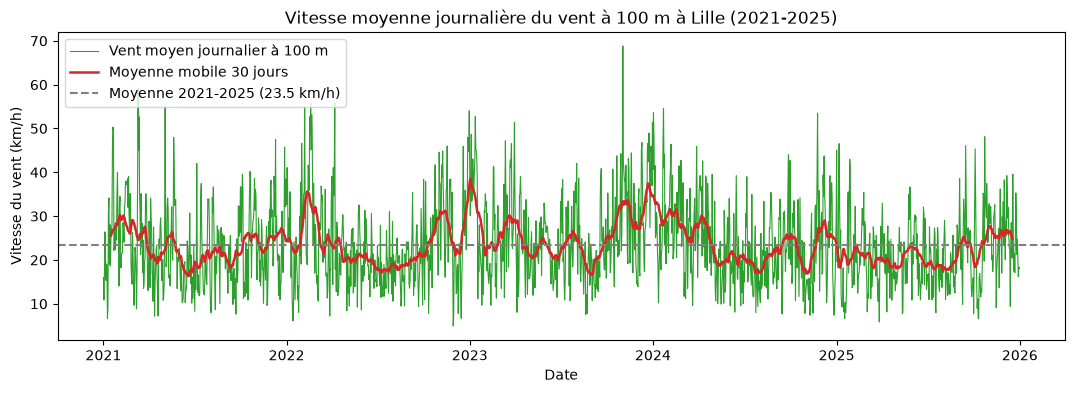

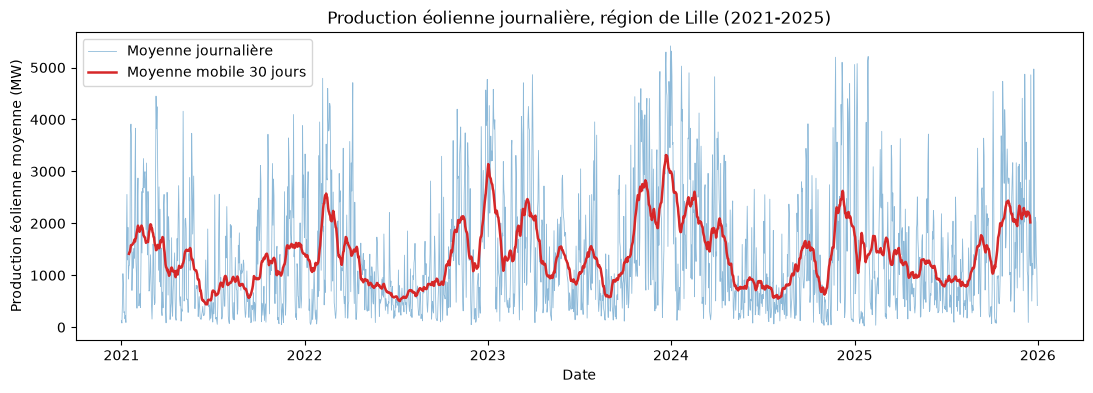

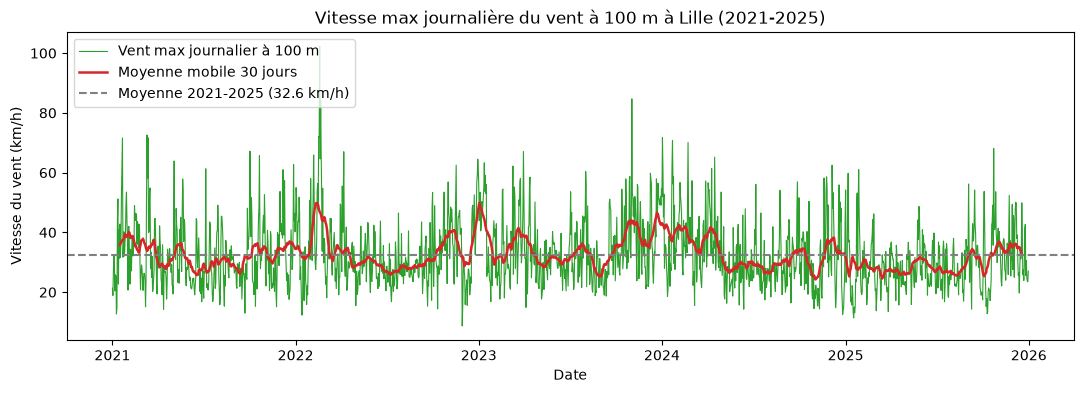

In [18]:

from src.stats_graph import tracer_graphique_eolien
from src.meteo import tracer_vent_moyen_jour
from src.meteo import tracer_vent_max_jour

ville = "lille" #On a choisit Lille car il  y a une grande production éolien selon le graphique détaillant le mix énérgétique de chaque région
tracer_vent_moyen_jour(meteo, ville)
tracer_graphique_eolien(donnees, ville)
tracer_vent_max_jour(meteo, ville)


En regardant les moyennes mobiles, on observe clairement que les graphiques sont très similaires (pics et chutes au même moment, même forme à peu de chose près).

Cela confirme (sans grande surprise) notre hypothèse de causalité entre la production éolienne et la vitesse du vent. À noter tout de même que nos données ont été enregistrées dans les villes respectives et donc potentiellement loin des parcs éoliens (cela ne semble pas avoir posé trop de problèmes).

On va étudier cet effet plus en détail pour aller plus loin et être plus rigoureux.

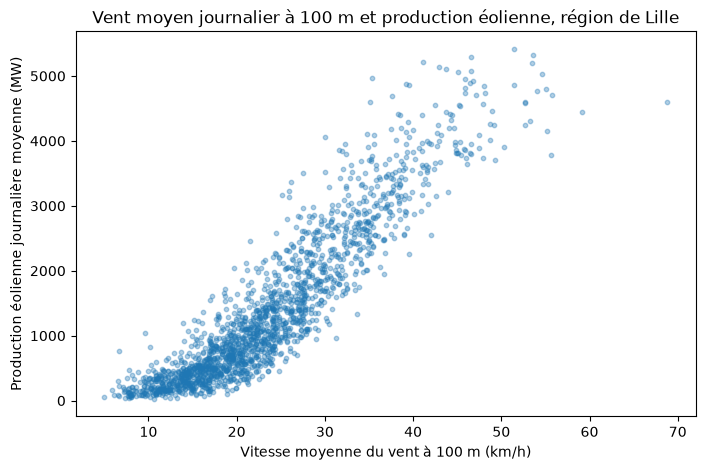

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from src.stats_graph import tracer_scatter_vent_eolien


tracer_scatter_vent_eolien(donnees, "lille")


On n'observe pas vraiment de relation linéaire entre les deux variables. La relation semble plutôt suivre une courbe non linéaire, avec un début relativement plat, suivi d'une augmentation beaucoup plus rapide de la production lorsque la vitesse du vent augmente.

En effectuant quelques recherches, on retrouve une explication physique à cette forme de courbe. En effet, la puissance disponible dans le vent est proportionnelle au cube de sa vitesse, selon la formule :

$$
P_{\text{vent}} = \frac{1}{2}\rho A v^3
$$

où $\rho$ représente la masse volumique de l'air, $A$ la surface balayée par les pales et $v$ la vitesse du vent.

Cela signifie qu'à surface balayée et conditions identiques, doubler la vitesse du vent revient théoriquement à multiplier par 8 la puissance disponible. La production électrique augmente donc très rapidement avec la vitesse du vent.

La courbe réelle d'une éolienne est dans les fait divisées en plusieurs phases :
- En dessous d'une certaine vitesse (vitesse de démarrage), elle ne produit pas d'électricité. (on l'observe bien sur nos graphique, c'est notre début plat)
- Ensuite, la production augmente fortement, approximativement selon une loi cubique (de même on l'observe avec sa progression très rapide)
- Au-delà, elle est généralement maintenue à un niveau relativement constant afin de protéger les équipements.
- Enfin, en cas de vent trop violent, l'éolienne s'arrête pour des raisons de sécurité. (On a pas ici trouvé de points correspondants.)

La forme que nous observons dans nos données est donc cohérente avec le fonctionnement physique des éoliennes !
Source :  https://fr.wikipedia.org/wiki/%C3%89olienne

### Production 2 : La production solaire suit l'ensoleillement : nulle la nuit, maximale vers midi et en été

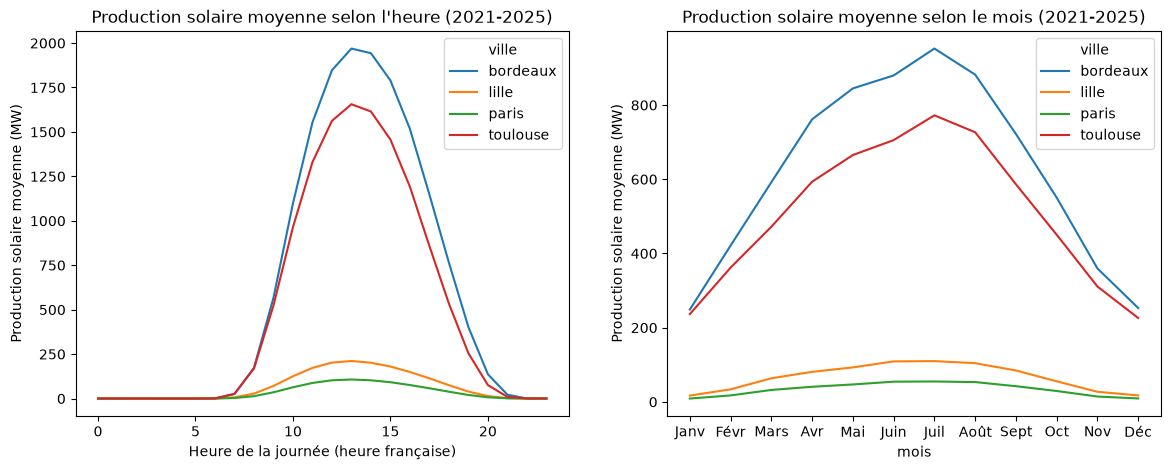

In [20]:
#Hypothèse solaire : on extrait l'heure de la journée et le mois (time est déjà en heure française)
donnees["heure"] = donnees["time"].dt.hour
donnees["mois"] = donnees["time"].dt.month

#On compare deux régions très solaires du Sud et deux régions du Nord
villes = ["toulouse", "bordeaux", "paris", "lille"]
d = donnees[donnees["ville"].isin(villes)]

#Production solaire moyenne pour chaque heure (puis chaque mois), une colonne par ville
profil_heure = d.groupby(["heure", "ville"])["solaire"].mean().unstack()
profil_mois = d.groupby(["mois", "ville"])["solaire"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

profil_heure.plot(ax=axes[0])
axes[0].set_title("Production solaire moyenne selon l'heure (2021-2025)")
axes[0].set_xlabel("Heure de la journée (heure française)")
axes[0].set_ylabel("Production solaire moyenne (MW)")

profil_mois.plot(ax=axes[1])
noms_mois = ["Janv", "Févr", "Mars", "Avr", "Mai", "Juin",
             "Juil", "Août", "Sept", "Oct", "Nov", "Déc"]
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(noms_mois)

axes[1].set_title("Production solaire moyenne selon le mois (2021-2025)")

axes[1].set_ylabel("Production solaire moyenne (MW)")

plt.show()


1. *Selon l'heure.* Le premier graphique confirme notre hypothèse : la production solaire devient non nulle vers 7 h (lever du soleil), atteint son maximum vers 13 h (le midi solaire, décalé par l'heure d'été) et s'annule vers 21 h (coucher du soleil).
2. *Selon le mois.* Le second graphique montre que la production est maximale en été, avec un pic en juillet : à Bordeaux et Toulouse, elle est 3 à 4 fois plus élevée en juillet qu'en janvier.
3. *Selon la région.* Les régions du Sud-Ouest (Bordeaux, Toulouse) produisent beaucoup plus que celles du Nord (Paris, Lille) : en juillet, environ 8 fois plus à Bordeaux qu'à Lille. Cet écart s'explique par l'ensoleillement, mais aussi par le nombre de panneaux installés dans chaque région.


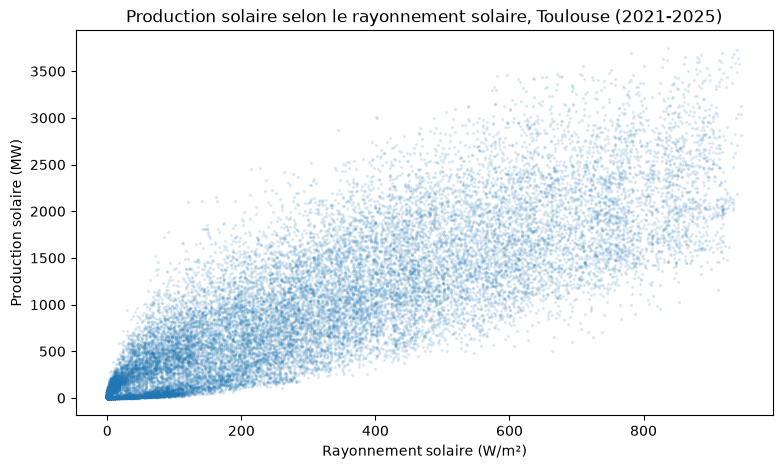

In [21]:
ville = "toulouse"
t = donnees[donnees["ville"] == ville]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(t["shortwave_radiation"], t["solaire"], s=2, alpha=0.1)
ax.set_title("Production solaire selon le rayonnement solaire, " + ville.capitalize() + " (2021-2025)")
ax.set_xlabel("Rayonnement solaire (W/m²)")
ax.set_ylabel("Production solaire (MW)")
plt.show()


**Étude de cas sur Toulouse**

Ce graphique montre, heure par heure, le lien entre le rayonnement solaire mesuré à Toulouse et la production solaire de toute la région Occitanie.

1. *Le paquet de points en (0, 0).* Ces points correspondent à la nuit, soit près de la moitié des heures : c'est le constat le plus sûr que l'on peut tirer de ce graphique. La nuit, la production solaire est nulle.
2. *Une relation croissante presque linéaire.* Plus le rayonnement est fort, plus la région produit.
3. *Une dispersion qui s'élargit.* Pour un même rayonnement, par exemple 600 W/m², la production varie du simple au double. Trois explications plausibles :
   - le parc solaire a beaucoup grandi entre 2021 et 2025 : le même soleil produit plus de MW en 2025 qu'en 2021, car il y a plus de panneaux ;
   - on mesure le soleil en un seul point (Toulouse), alors que la production vient de panneaux répartis dans toute l'Occitanie ;
   - les panneaux perdent du rendement quand ils chauffent.


In [22]:
correl_solaire = donnees.groupby("ville").apply(correlation, "shortwave_radiation", "solaire").sort_values()
display(correl_solaire)


ville
dijon         0.830548
rennes        0.831783
strasbourg    0.838301
lille         0.842761
paris         0.849774
orleans       0.857390
nantes        0.859363
rouen         0.874335
lyon          0.877835
toulouse      0.908257
bordeaux      0.914521
marseille     0.921366
dtype: float64

La corrélation entre le rayonnement et la production solaire est positive et très forte dans toutes les régions, de 0,83 (Dijon) à 0,92 (Marseille), ce qui confirme notre hypothèse. Elle est la plus élevée dans les régions du Sud (Marseille, Bordeaux, Toulouse, toutes au-dessus de 0,9), où le parc solaire est le plus important.


### Production 3 :La production hydraulique dépend des précipitations, avec un décalage dans le temps.

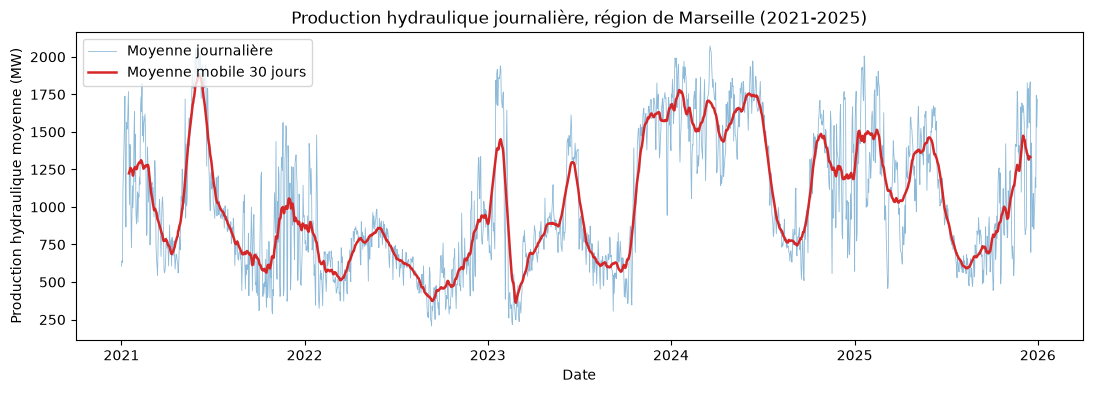

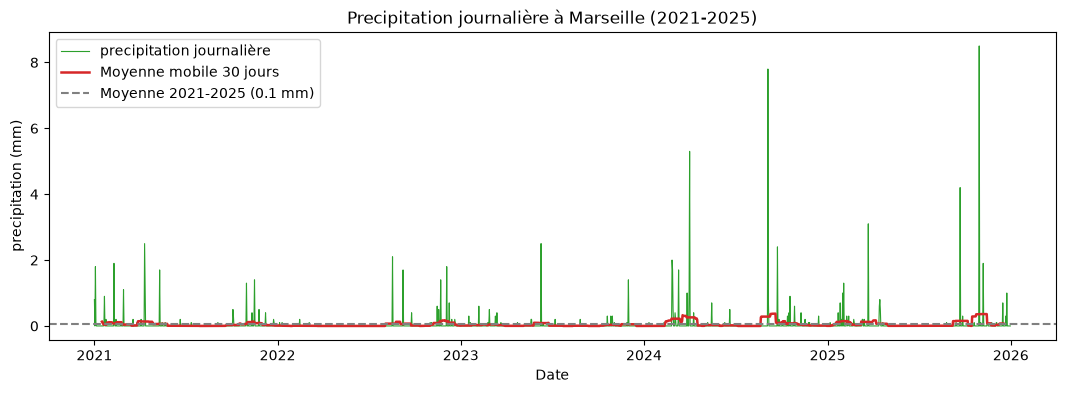

In [23]:
from src.stats_graph import tracer_graphique_hydrau, tracer_hydrau_mois
from src.meteo import tracer_precipitation_jour, tracer_cumul_mensuel_precipitation

ville="marseille"

tracer_graphique_hydrau(donnees, ville, col_prod="hydraulique", groupe="ville")
tracer_precipitation_jour(meteo, ville)


Si l'on essaie d'appliquer la même méthode que dans « Production 1 », le résultat n'est pas très lisible, car les valeurs extrêmes écrasent le reste du graphique. Plutôt que de supprimer ces outliers, nous allons donc effectuer une agrégation des données par mois. Cela permettra de lisser les variations ponctuelles tout en conservant l'ensemble des observations.

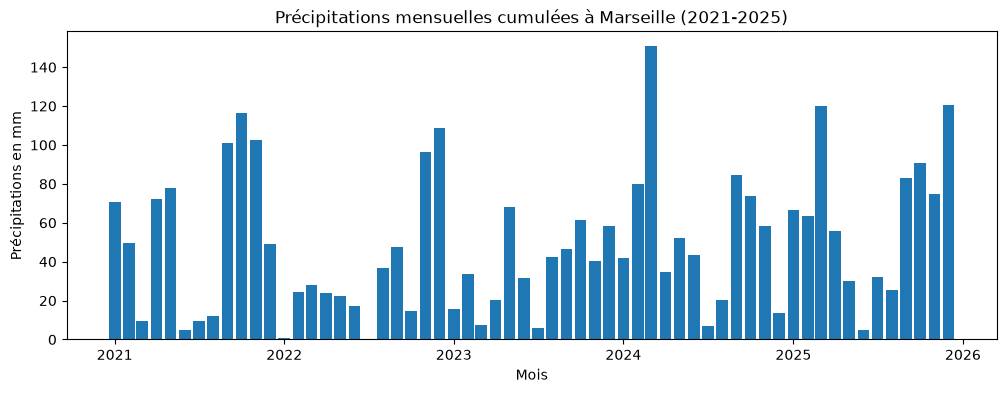

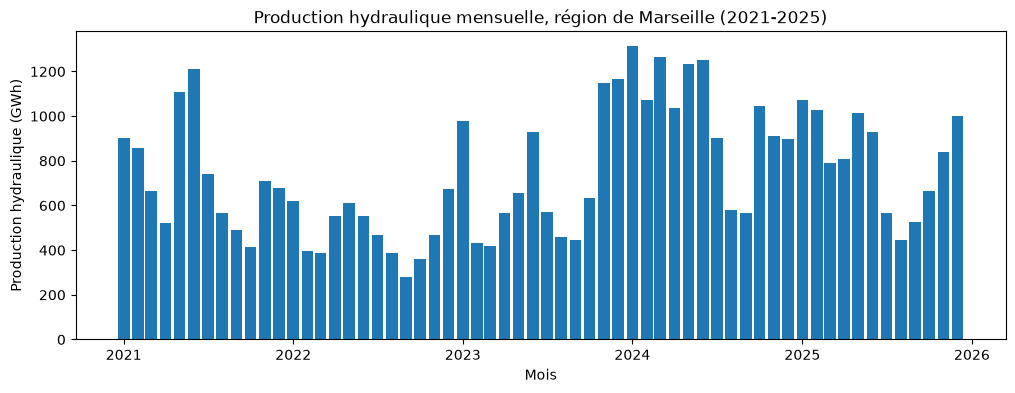

In [24]:
from src.stats_graph import tracer_graphique_hydrau, tracer_hydrau_mois
from src.meteo import tracer_precipitation_jour, tracer_cumul_mensuel_precipitation

ville="marseille"

tracer_cumul_mensuel_precipitation(meteo,ville)
tracer_hydrau_mois(donnees, ville, col_prod="hydraulique")

Ici la conclusion est nettement moins claire que dans production #1 (ce qui est attendu). On va essayer tout de même de vérifier si ce n'est pas simplement du à un décalage comme on en avait fait l'hypothèse.

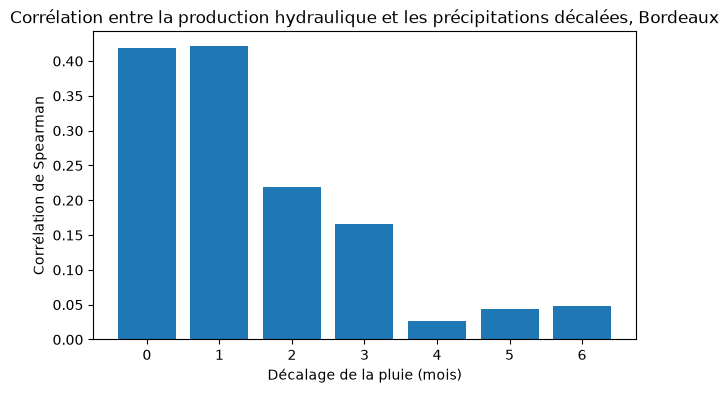

In [25]:
import pandas as pd 
from src.meteo import cumul_mensuel_precipitation
from src.stats_graph import production_mensuelle, corr, tracer_graph_hydrau_pluie, tracer_scatter_pluie_prec


ville = "bordeaux"   # Auvergne-Rhône-Alpes : région hydraulique majeure

pluie =cumul_mensuel_precipitation(meteo,ville)
pluie.index = pluie.index.tz_localize(None)          # même format d'index que la production
prod = production_mensuelle(donnees, ville, "hydraulique")
corr(pluie,prod,ville)


On fait alors l'hypothèse que le décalage de la pluie est de 1 mois. Cependant un coefficient de 0.4 n'est pas très impressionant...

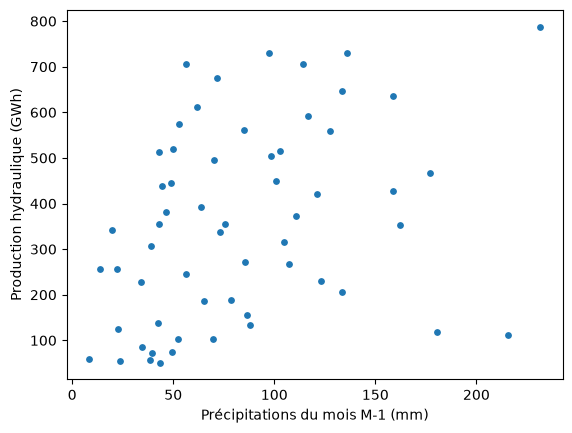

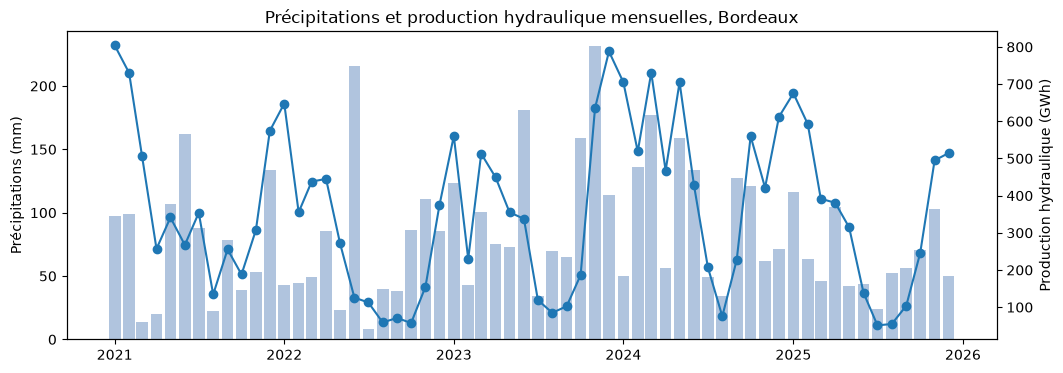

In [26]:
tracer_scatter_pluie_prec(pluie,prod,ville)
tracer_graph_hydrau_pluie(pluie,prod,ville)

On ne parvient pas réellement à mettre en évidence une corrélation, et encore moins une relation de causalité, entre les deux variables. Ce résultat est toutefois assez attendu : la production hydroélectrique dépend de nombreux facteurs qui ne se limitent pas aux précipitations. Elle dépend notamment de la gestion des barrages, des décisions d'ouverture des vannes, des réserves d'eau disponibles et de la demande en électricité.

Il est donc tout à fait normal que la simple mise en relation des précipitations et de la production hydraulique ne permette pas d'obtenir de résultats concluants. Cela montre également les limites de notre approche, qui ne prend pas en compte l'ensemble des facteurs influençant la production.

### Production 4 : La production nucléaire est peu sensible à la météo, sauf lors des canicules

In [27]:
#Hypothèse nucléaire : on ne garde que les régions qui ont des centrales (production moyenne > 0)
SEUIL_CANICULE = 30   # température maximale (°C) à partir de laquelle on parle de canicule
nuc_moyen = donnees.groupby("ville")["nucleaire"].mean()
villes_nucleaires = nuc_moyen[nuc_moyen > 0].index.tolist()
print("Régions avec centrales : " + str(villes_nucleaires))

#Échelle du jour : production nucléaire moyenne et température MAXIMALE du jour
#(c'est la chaleur de l'après-midi qui réchauffe les fleuves)
nuc_jour = (donnees[donnees["ville"].isin(villes_nucleaires)]
            .groupby(["ville", "jour"])
            .agg(nucleaire=("nucleaire", "mean"), tmax=("temperature_2m", "max"))
            .reset_index())
nuc_jour["jour"] = pd.to_datetime(nuc_jour["jour"])
nuc_jour["mois"] = nuc_jour["jour"].dt.month
nuc_jour["annee"] = nuc_jour["jour"].dt.year

#On compare uniquement les jours d'été entre eux : les centrales sont souvent en maintenance l'été,
#comparer l'été à l'hiver mélangerait l'effet de la chaleur et celui de la maintenance
ete = nuc_jour[nuc_jour["mois"].isin([6, 7, 8])].copy()
ete["canicule"] = ete["tmax"] >= SEUIL_CANICULE



Régions avec centrales : ['bordeaux', 'lille', 'lyon', 'orleans', 'rouen', 'strasbourg', 'toulouse']


Pour tester cette hypothèse, nous avons fait trois choix :

- **Ne garder que les 7 régions qui produisent du nucléaire** (Bordeaux, Lille, Lyon, Orléans, Rouen, Strasbourg, Toulouse). Les cinq autres n'ont aucune centrale et leur production toujours nulle n'apporte aucune information.
- **Travailler à l'échelle du jour avec la température maximale**, et non la moyenne : c'est la chaleur de l'après-midi qui réchauffe les fleuves, alors que la moyenne journalière est tirée vers le bas par la nuit.
- **Ne comparer que des jours d'été (juin à août) entre eux.** EDF programme une grande partie des maintenances l'été, quand la demande est faible : comparer l'été à l'hiver mélangerait l'effet de la chaleur avec celui des arrêts programmés.

Nous qualifions de « canicule » un jour d'été dont la température maximale atteint 30 °C. Ce seuil est un choix de notre part : il ne correspond pas à la définition officielle de Météo-France, qui repose sur plusieurs jours consécutifs et des seuils propres à chaque département.

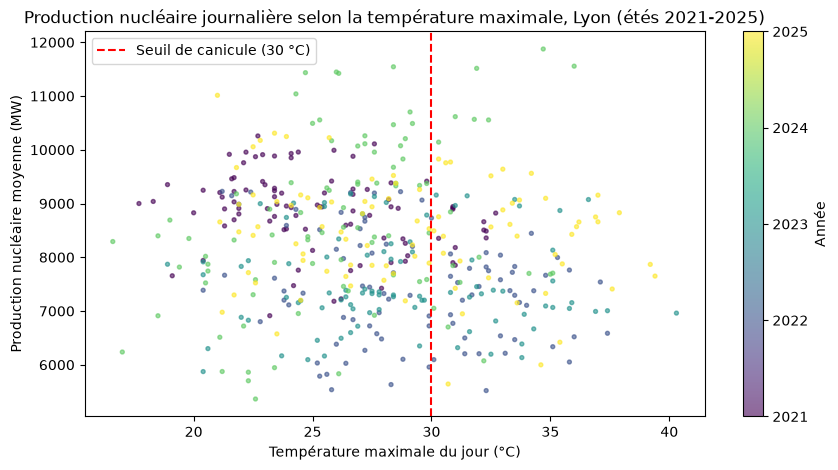

In [28]:
ville = "lyon"
v = ete[ete["ville"] == ville]

fig, ax = plt.subplots(figsize=(10, 5))
nuage = ax.scatter(v["tmax"], v["nucleaire"], s=8, alpha=0.6, c=v["annee"])
fig.colorbar(nuage, label="Année", ticks=[2021, 2022, 2023, 2024, 2025])
ax.axvline(SEUIL_CANICULE, color="red", linestyle="--", label="Seuil de canicule (" + str(SEUIL_CANICULE) + " °C)")
ax.set_title("Production nucléaire journalière selon la température maximale, " + ville.capitalize() + " (étés 2021-2025)")
ax.set_xlabel("Température maximale du jour (°C)")
ax.set_ylabel("Production nucléaire moyenne (MW)")
ax.legend()
plt.show()


**I/ Constat**

La chaleur n'a pas d'effet visible sur la production nucléaire de la région lyonnaise.

**II/ Lecture**

1. *Pas de relation nette avec la température.* Le nuage est à peu près horizontal : on trouve des jours à 6 000 MW comme à 11 000 MW, qu'il fasse 22 °C ou 35 °C.
2. *Les couleurs sont regroupées par niveau.*
   - Les points bleu-vert foncé (2022-2023) sont plutôt en bas, entre 6 000 et 7 500 MW. En 2022, de nombreux réacteurs étaient à l'arrêt à cause de la corrosion sous contrainte.
   - Les points vert clair (2024) et jaunes (2025) sont plutôt en haut, entre 9 000 et 11 500 MW, une fois le parc revenu en service.

   La disponibilité des réacteurs fait donc bien plus varier la production que la température.

**III/ Conclusion**

L'hypothèse n'est pas confirmée à cette échelle.

**IV/ Limites**

- On ne regarde qu'une région sur ce graphique. Le tableau des écarts ci-dessous complète l'analyse, mais les résultats varient beaucoup d'une région à l'autre (de -15 % à +10 %), ce qui confirme qu'on ne voit pas d'effet clair et régulier.
- La température de l'air à Lyon n'est qu'un indicateur indirect : ce qui contraint vraiment les centrales, c'est la température et le débit du fleuve, que nous n'avons pas. Pour aller plus loin, il faudrait des données hydrologiques, par exemple celles de Hub'Eau.


In [29]:
def ecart_canicule(df):
    """Écart (en %) de production nucléaire moyenne entre jours de canicule et autres jours d'été, par ville."""
    moyennes = df.groupby(["ville", "canicule"])["nucleaire"].mean().unstack()
    return ((moyennes[True] / moyennes[False] - 1) * 100).round(1)

comparaison = pd.DataFrame({
    "jours_canicule": ete.groupby("ville")["canicule"].sum(),
    "ecart_toutes_annees_%": ecart_canicule(ete),
    "ecart_sans_2022_%": ecart_canicule(ete[ete["annee"] != 2022]),
})
display(comparaison)


,jours_canicule,ecart_toutes_annees_%,ecart_sans_2022_%
ville,,,
bordeaux,110,-9.3,1.7
lille,21,-8.8,-5.5
lyon,137,-4.7,-3.1
orleans,52,1.2,0.9
rouen,25,-11.3,10.0
strasbourg,70,-15.3,-3.7
toulouse,164,-12.1,-15.1


**Écart de production nucléaire entre jours de canicule et autres jours d'été**

Pour chaque région, le tableau donne le nombre de jours de canicule (température maximale ≥ 30 °C) entre 2021 et 2025, puis l'écart (en %) entre la production nucléaire moyenne des jours de canicule et celle des autres jours d'été.

1. Toutes années confondues:
=> la production est plus faible les jours de canicule dans six régions sur sept, de -4,7 % (Lyon) à -15,3 % (Strasbourg). Ce résultat est cependant biaisé par **2022** : cet été a été à la fois très chaud et marqué par l'arrêt de nombreux réacteurs pour des problèmes de corrosion. Une partie de la baisse attribuée à la chaleur vient en réalité de ces arrêts.

2. Sans 2022, les écarts se réduisent fortement et changent parfois de signe :
=> seules Toulouse (-15,1 %) et, dans une moindre mesure, Lille (-5,5 %), Strasbourg (-3,7 %) et Lyon (-3,1 %) gardent une baisse. Le cas de Toulouse est cohérent avec l'hypothèse : la centrale de Golfech est refroidie par la Garonne, dont le débit baisse fortement l'été ;
=> Bordeaux (+1,7 %) et Orléans (+0,9 %) ne montrent pas d'effet ;
=> Rouen (+10,0 %) montre même une hausse, qui ne peut pas s'expliquer par la météo : elle reflète plutôt le calendrier des maintenances sur un petit nombre de jours de canicule (25).

3. Conclusion 
A l'échelle régionale et journalière, nous ne mettons pas en évidence d'effet net et régulier de la chaleur sur la production nucléaire. Les baisses liées aux fortes chaleurs existent, mais elles concernent quelques réacteurs pendant quelques jours, et elles sont faibles devant les variations dues à la disponibilité du parc (maintenances, arrêts). Comme le montrait le graphique de Lyon, l'année explique davantage la production que la température.

4. Limites :
Certaines régions comptent peu de jours de canicule (21 à Lille, 25 à Rouen), ce qui rend les écarts fragiles. Surtout, la température de l'air n'est qu'un indicateur indirect : ce qui contraint les centrales, c'est la température et le débit des fleuves, que nous n'avons pas mesurés.


# IV. Conclusion

**Bilan de nos hypothèses**

- **Consommation et froid : confirmée.** Sous 15 °C, la consommation augmente fortement quand la température baisse, dans toutes les régions (corrélation comprise entre -0,79 et -0,88). C'est l'effet du chauffage électrique, très répandu en France.
- **Consommation et chaleur : nuancée.** La hausse liée à la climatisation n'apparaît nettement que dans le Sud (corrélation de 0,77 à Marseille et 0,66 à Toulouse au-dessus de 20 °C), et elle est quasi nulle dans le Nord. Elle commence vers 20 °C de moyenne journalière : notre seuil de 27 °C était trop élevé.
- **Éolien : confirmée.** La production suit la vitesse du vent, selon une relation non linéaire cohérente avec la physique des éoliennes (seuil de démarrage, puis croissance rapide, la puissance du vent variant avec le cube de sa vitesse).
- **Solaire : confirmée.** La production est nulle la nuit, maximale vers 13 h et en juillet, et très fortement corrélée au rayonnement solaire (de 0,83 à 0,92 selon les régions).
- **Hydraulique : non mise en évidence.** Même avec un décalage d'un mois, la corrélation avec les précipitations reste faible (environ 0,4).
- **Nucléaire : non confirmée à notre échelle.** Les écarts de production entre jours de canicule et autres jours d'été sont faibles et de sens variable selon les régions ; ils sont surtout dominés par la disponibilité des réacteurs, comme l'a montré l'année 2022.


Les conditions météorologiques expliquent fortement ce qui n'est pas pilotable : la consommation, à travers le chauffage, et la production éolienne et solaire, qui dépendent directement du vent et du soleil. Elles expliquent en revanche peu les filières pilotables : la production hydraulique et la production nucléaire résultent avant tout de décisions humaines (gestion des barrages, calendrier de maintenance des réacteurs), la météo n'étant qu'un facteur parmi d'autres. La météo explique donc une part importante de la consommation et de la production d'électricité en France, mais cette part dépend fortement de la filière.

**Limites**

- La météo de chaque région est approchée par celle de sa plus grande ville, ce qui est raisonnable pour la température mais plus fragile pour le vent et l'ensoleillement.
- Les seuils utilisés (15 °C, 27 °C, 30 °C) sont des choix de notre part.
- Nous mesurons des corrélations, et non des relations de causalité démontrées, même si les mécanismes physiques sont connus.
- Seules quatre filières ont été étudiées, et certains facteurs déterminants n'ont pas été pris en compte : débit et température des fleuves, fonte des neiges, calendrier des maintenances.

**Pistes d'amélioration**

On pourrait utiliser la météo de plusieurs villes par région, intégrer des données hydrologiques (par exemple celles de Hub'Eau une autre API) pour l'hydraulique et le nucléaire, et estimer une régression pour quantifier les effets (combien de MW par degré, par exemple) plutôt que de simples corrélations.
